# 01 — Linear Algebra for ML

**Overview:** scalars → vectors → matrices → tensors, dot product, matrix multiplication,
transpose, norms, eigenvalues/eigenvectors, and SVD intuition via a tiny PCA-by-hand example.

**Required libraries:** `numpy`, `matplotlib`.

Each section: intuition → equation → small example → Python → ML usage.

Connects to: `02_numpy` (same operations, now with mathematical meaning attached). Leads to:
`02_probability_statistics.ipynb`.

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("numpy:", np.__version__)
rng = np.random.default_rng(42)


numpy: 2.5.3


## 1. Scalars, vectors, matrices, tensors

💡 **Intuition:** a scalar is a single number; a vector is a list of numbers (a point/direction
in space); a matrix is a 2D grid of numbers (a linear transformation); a tensor generalizes this
to any number of axes.

In [2]:
scalar = 5.0
vector = np.array([1.0, 2.0, 3.0])             # shape (3,)
matrix = np.array([[1.0, 2.0], [3.0, 4.0]])     # shape (2,2)
tensor = rng.normal(size=(2, 3, 4))             # shape (2,3,4)

for name, x in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("tensor", tensor)]:
    shape = getattr(x, "shape", ())
    print(f"{name}: shape={shape}")


scalar: shape=()
vector: shape=(3,)
matrix: shape=(2, 2)
tensor: shape=(2, 3, 4)


## 2. Dot product

**Equation:** `u · v = Σᵢ uᵢ vᵢ`

💡 **Intuition:** the dot product measures how much two vectors point in the same direction —
zero if perpendicular, maximal if parallel.

In [3]:
u = np.array([1.0, 0.0])
v_parallel = np.array([2.0, 0.0])
v_perp = np.array([0.0, 2.0])

print("u . v_parallel (same direction):", np.dot(u, v_parallel))
print("u . v_perp (perpendicular):     ", np.dot(u, v_perp))

assert np.dot(u, v_perp) == 0.0
assert np.dot(u, v_parallel) > 0.0

print("\nML usage: a linear layer's output for one neuron is exactly a dot product between the "
      "input vector and that neuron's weight vector, plus a bias.")


u . v_parallel (same direction): 2.0
u . v_perp (perpendicular):      0.0

ML usage: a linear layer's output for one neuron is exactly a dot product between the input vector and that neuron's weight vector, plus a bias.


## 3. Matrix multiplication and transpose

**Equation:** `(A @ B)[i,j] = Σₖ A[i,k] B[k,j]`, requiring `A`'s columns == `B`'s rows.

In [4]:
A = rng.normal(size=(3, 4))
B = rng.normal(size=(4, 2))
C = A @ B
print("A:", A.shape, "@ B:", B.shape, "-> C:", C.shape)
assert C.shape == (3, 2)

# from-scratch matmul to make the formula concrete
def matmul_from_scratch(A, B):
    m, n = A.shape
    n2, p = B.shape
    assert n == n2
    out = np.zeros((m, p))
    for i in range(m):
        for j in range(p):
            out[i, j] = sum(A[i, k] * B[k, j] for k in range(n))
    return out

C_manual = matmul_from_scratch(A, B)
assert np.allclose(C, C_manual)
print("from-scratch matmul matches A @ B:", np.allclose(C, C_manual))

# Transpose identity: (A @ B).T == B.T @ A.T
assert np.allclose((A @ B).T, B.T @ A.T)
print("(A @ B).T == B.T @ A.T:", np.allclose((A @ B).T, B.T @ A.T))


A: (3, 4) @ B: (4, 2) -> C: (3, 2)
from-scratch matmul matches A @ B: True
(A @ B).T == B.T @ A.T: True


## 4. Norms

**Equation:** `‖v‖₂ = sqrt(Σ vᵢ²)` — the Euclidean length of a vector.

In [5]:
v = np.array([3.0, 4.0])
l2_norm = np.linalg.norm(v)
print("‖v‖₂:", l2_norm, "(a 3-4-5 triangle, so this should be 5.0)")
assert np.isclose(l2_norm, 5.0)

print("\nML usage: L2 regularization penalizes ‖W‖₂ to discourage large weights; "
      "Euclidean distance between embeddings is exactly this norm applied to a difference vector.")


‖v‖₂: 5.0 (a 3-4-5 triangle, so this should be 5.0)

ML usage: L2 regularization penalizes ‖W‖₂ to discourage large weights; Euclidean distance between embeddings is exactly this norm applied to a difference vector.


## 5. Eigenvalues and eigenvectors

💡 **Intuition:** for a square matrix `A`, an eigenvector `v` is a direction `A` only *scales*
(by its eigenvalue `λ`), never rotates: `A v = λ v`.

In [6]:
A_sym = np.array([[2.0, 1.0], [1.0, 2.0]])   # symmetric -> real eigenvalues/eigenvectors
# np.linalg.eigh (not eig) is the right tool for symmetric matrices: it guarantees real
# eigenvalues/eigenvectors instead of a general complex-capable solver.
eigenvalues, eigenvectors = np.linalg.eigh(A_sym)
print("eigenvalues:", eigenvalues)
print("eigenvectors (columns):\n", eigenvectors)

for i in range(2):
    lam, v = eigenvalues[i], eigenvectors[:, i]
    lhs = A_sym @ v
    rhs = lam * v
    assert np.allclose(lhs, rhs)
print("\nverified A @ v == lambda * v for each eigenpair.")

# Reconstruct A from its eigendecomposition: A == V @ diag(lambda) @ V_inv
V, L = eigenvectors, np.diag(eigenvalues)
A_reconstructed = V @ L @ np.linalg.inv(V)
assert np.allclose(A_sym, A_reconstructed)
print("reconstructed A from eigendecomposition matches original:", np.allclose(A_sym, A_reconstructed))


eigenvalues: [1. 3.]
eigenvectors (columns):
 [[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]

verified A @ v == lambda * v for each eigenpair.
reconstructed A from eigendecomposition matches original: True


## 6. SVD and a tiny PCA-by-hand

💡 **Intuition:** SVD decomposes *any* matrix as `A = U Σ Vᵗ` (rotate, scale, rotate). PCA uses
the eigenvectors of the data's covariance matrix (equivalently, SVD of the centered data) as new
axes ranked by how much variance they capture — the top eigenvector is the direction of maximum
spread.

covariance matrix:
 [[0.85841244 0.68408048]
 [0.68408048 0.63660171]]

eigenvalues (variance explained per component): [1.44051942 0.05449473]
top principal direction: [-0.76158839 -0.64806105]

original shape: (200, 2) -> projected (1D) shape: (200,)


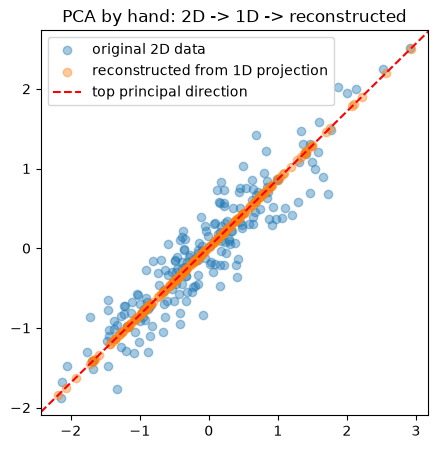


variance retained by 1 component: 96.4%


In [7]:
# A 2D dataset with correlated features.
n_points = 200
x1 = rng.normal(size=n_points)
x2 = 0.8 * x1 + rng.normal(scale=0.3, size=n_points)
data = np.column_stack([x1, x2])          # shape (200, 2)

data_centered = data - data.mean(axis=0)
cov = np.cov(data_centered, rowvar=False)  # (2,2) covariance matrix
print("covariance matrix:\n", cov)

eigvals, eigvecs = np.linalg.eigh(cov)  # symmetric covariance matrix -> real eigenpairs
order = np.argsort(eigvals)[::-1]          # sort descending by variance explained
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
top_direction = eigvecs[:, 0]

print("\neigenvalues (variance explained per component):", eigvals)
print("top principal direction:", top_direction)

# Project the 2D data onto its single top principal component (2D -> 1D).
projected_1d = data_centered @ top_direction
reconstructed_2d = np.outer(projected_1d, top_direction) + data.mean(axis=0)

print("\noriginal shape:", data.shape, "-> projected (1D) shape:", projected_1d.shape)
assert projected_1d.shape == (n_points,)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(data[:, 0], data[:, 1], alpha=0.4, label="original 2D data")
ax.scatter(reconstructed_2d[:, 0], reconstructed_2d[:, 1], alpha=0.4, label="reconstructed from 1D projection")
ax.axline((data.mean(0)[0], data.mean(0)[1]), slope=top_direction[1] / top_direction[0],
          color="red", linestyle="--", label="top principal direction")
ax.legend(); ax.set_title("PCA by hand: 2D -> 1D -> reconstructed")
plt.show()

variance_retained = eigvals[0] / eigvals.sum()
print(f"\nvariance retained by 1 component: {variance_retained:.1%}")
assert variance_retained > 0.8   # the features were constructed to be highly correlated


## 7. Connection to what's next

The gradient of a loss function — used by gradient descent in `03_calculus_and_gradient_descent.ipynb`
— is itself a vector, and every step of gradient descent is a vector operation exactly like the
ones in this notebook.

## 8. Interview questions
1. Why does `A @ B` require `A`'s number of columns to equal `B`'s number of rows?
2. What do eigenvectors of a covariance matrix represent in PCA, and why sort by eigenvalue?
3. What's the geometric meaning of the dot product being zero?
4. How does SVD generalize eigendecomposition to non-square matrices?
5. Why is L2 regularization expressed in terms of a vector norm?

## 9. Exercises
1. Verify `‖u + v‖ ≤ ‖u‖ + ‖v‖` (triangle inequality) for two random vectors.
2. Reduce a 3-feature correlated synthetic dataset to 2 principal components and report variance retained.
3. Implement matrix-vector multiplication from scratch and verify against `A @ v`.

## 10. Summary

✅ Dot products and matmul are the two operations underlying every linear layer; eigenvectors of
a covariance matrix give PCA's principal components. Next: `02_probability_statistics.ipynb`.